In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import regionmask
import xarray as xr
from matplotlib.gridspec import GridSpec
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

from fast_o3_iv import utils
from fast_o3_iv.config import INTERIM_DATA_DIR
from fast_o3_iv.modeling.train import DatasetConfig
import fast_o3_iv.bias_correction as bc

In [3]:
baseline_years = slice("1990", "2014")

In [4]:
config_hist = DatasetConfig(
            source_id = 'CESM2-WACCM6',
            cmip_experiment_id = 'historical',
            variable_setname = 'setC',
            year_range = range(1975,2015)
        )
config_ssp245 = DatasetConfig(
            source_id = config_hist.source_id,
            cmip_experiment_id = 'ssp245',
            variable_setname = config_hist.variable_setname,
            year_range = range(2015,2055)
        )

In [22]:
file_path = bc.return_osdma8_bc_path("inference", config_hist, "GPR-local")
hist_osdma8 = xr.open_dataset(file_path)
hist_osdma8_1990_2014 = hist_osdma8.sel(time=baseline_years)

file_path = bc.return_osdma8_bc_path("inference", config_ssp245, "GPR-local")
ssp245_osdma8 = xr.open_dataset(file_path)


In [6]:
# load observation osdma8
ramp_osdma8 = xr.open_dataset((
        INTERIM_DATA_DIR
        / "RAMP"
        / "Jacob_wRAMP_OSDMA8_1990_2017.nc"))
ramp_osdma8_1990_2014 = ramp_osdma8.sel(time=baseline_years)

In [23]:
regions = regionmask.defined_regions.ar6.land 

mask2d = regions.mask(ramp_osdma8_1990_2014) 
ramp_eas = ramp_osdma8_1990_2014.where(mask2d == regions.map_keys("EAS"), drop=True)
ramp_wce = ramp_osdma8_1990_2014.where(mask2d == regions.map_keys("WCE"), drop=True)

mask2d = regions.mask(hist_osdma8_1990_2014) 
hist_eas = hist_osdma8_1990_2014.where(mask2d == regions.map_keys("EAS"), drop=True)
hist_wce = hist_osdma8_1990_2014.where(mask2d == regions.map_keys("WCE"), drop=True)

# not just baseline years
mask2d = regions.mask(ssp245_osdma8) 
ssp_eas = ssp245_osdma8.where(mask2d == regions.map_keys("EAS"), drop=True)
ssp_wce = ssp245_osdma8.where(mask2d == regions.map_keys("WCE"), drop=True)

In [24]:
hist_eas_forced = hist_eas.mean(dim=['ensemble_member'])
hist_wce_forced = hist_wce.mean(dim=['ensemble_member'])

ssp_eas_forced = ssp_eas.mean(dim=['ensemble_member'])
ssp_wce_forced = ssp_wce.mean(dim=['ensemble_member'])

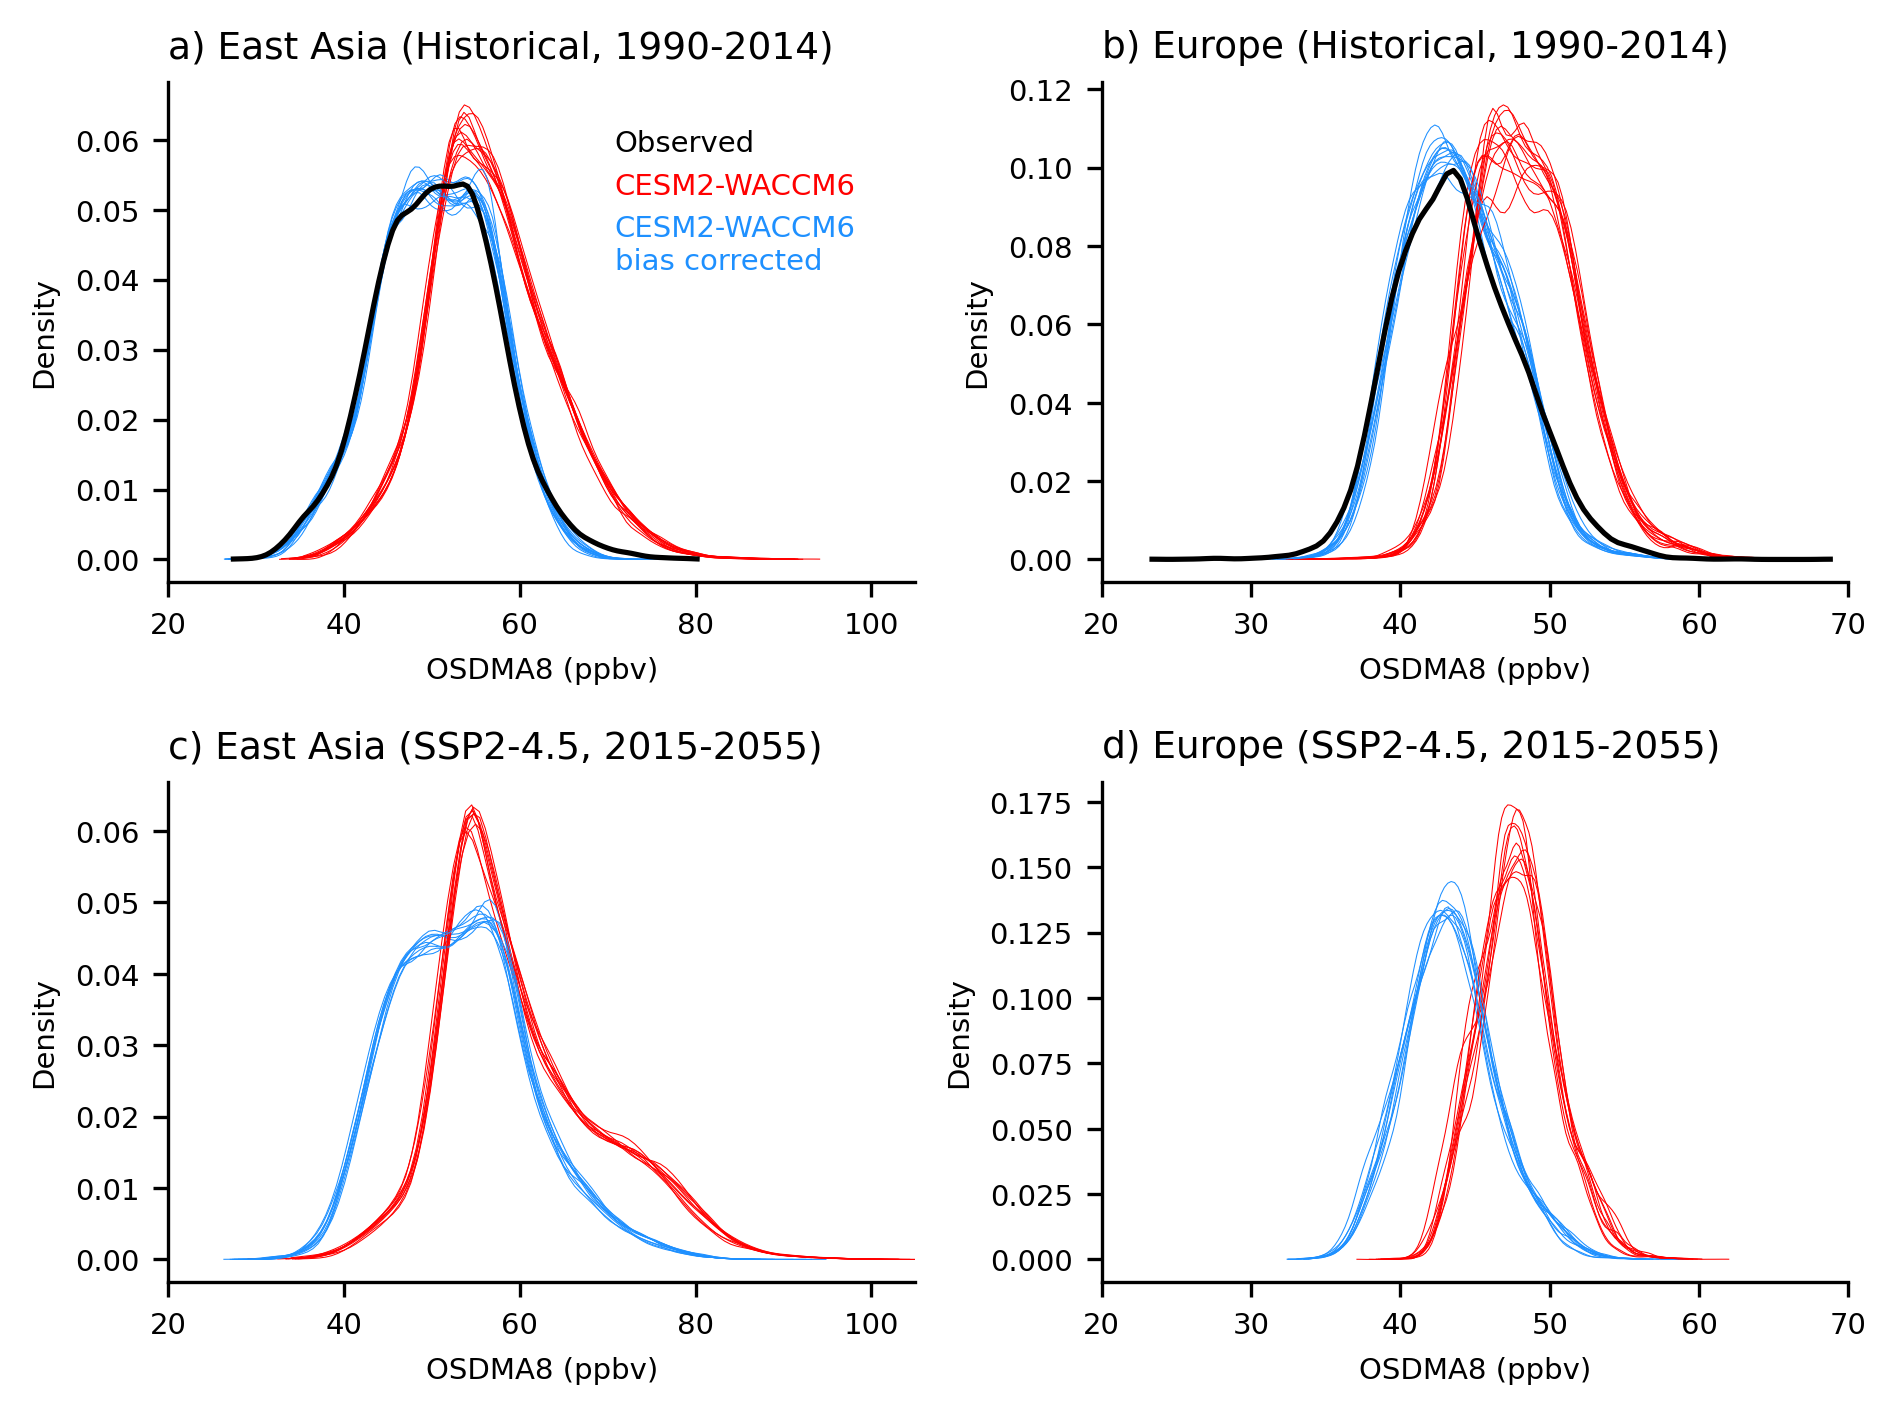

In [61]:

fig_width_in = 7
fig_height_in = 5
fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=300)

gs1 = GridSpec(
    2, 2,
    top=0.90, bottom=0.10, left=0.08, right=0.88,
    hspace=0.40, wspace=0.25
)

ax1 = fig.add_subplot(gs1[0, 0])
ax2 = fig.add_subplot(gs1[0, 1])

ax3 = fig.add_subplot(gs1[1, 0])
ax4 = fig.add_subplot(gs1[1, 1])

def plot_kde(osdma8, ax, color, label, lw=1.5):
    x = osdma8
    x = x[np.isfinite(x)]
    xs = np.linspace(x.min(), x.max(), 100)
    pdf = gaussian_kde(x)
    ax.plot(xs, pdf(xs), linewidth=lw, color=color, label=label)
    return ax


#plot_kde(hist_eas_forced.y_true.values.ravel(), ax1, color='red', label='CESM2-WACCM6')
#plot_kde(hist_wce_forced.y_true.values.ravel(), ax2, color='red', label='CESM2-WACCM6')

for member in range(13):
    hist_eas_member = hist_eas.isel(ensemble_member=member)
    plot_kde(
        hist_eas_member.y_true.values.ravel(), ax1,
        color='red',
        label='CESM2-WACCM6' if member == 0 else '_nolegend_',
        lw=0.25
    )
    plot_kde(
        hist_eas_member.y_true_bc.values.ravel(), ax1,
        color='dodgerblue',
        label='CESM2-WACCM6\nbias corrected' if member == 0 else '_nolegend_',
        lw=0.25
    )

    hist_wce_member = hist_wce.isel(ensemble_member=member)
    plot_kde(
        hist_wce_member.y_true.values.ravel(), ax2,
        color='red',
        label='CESM2-WACCM6' if member == 0 else '_nolegend_',
        lw=0.25
    )
    plot_kde(
        hist_wce_member.y_true_bc.values.ravel(), ax2,
        color='dodgerblue',
        label='CESM2-WACCM6\nbias corrected' if member == 0 else '_nolegend_',
        lw=0.25
    )
plot_kde(ramp_eas.ozone.values.ravel(), ax1, color='black', label='Observed', lw=1.25)
plot_kde(ramp_wce.ozone.values.ravel(), ax2, color='black', label='Observed', lw=1.25)

for member in range(10):
    ssp_eas_member = ssp_eas.isel(ensemble_member=member)
    plot_kde(
        ssp_eas_member.y_true.values.ravel(), ax3,
        color='red',
        label='CESM2-WACCM6' if member == 0 else '_nolegend_',
        lw=0.25
    )
    plot_kde(
        ssp_eas_member.y_true_bc.values.ravel(), ax3,
        color='dodgerblue',
        label='CESM2-WACCM6\nbias corrected' if member == 0 else '_nolegend_',
        lw=0.25
    )

    ssp_wce_member = ssp_wce.isel(ensemble_member=member)
    plot_kde(
        ssp_wce_member.y_true.values.ravel(), ax4,
        color='red',
        label='CESM2-WACCM6' if member == 0 else '_nolegend_',
        lw=0.25
    )
    plot_kde(
        ssp_wce_member.y_true_bc.values.ravel(), ax4,
        color='dodgerblue',
        label='CESM2-WACCM6\nbias corrected' if member == 0 else '_nolegend_',
        lw=0.25
    )

ax1.set_title("a) East Asia (Historical, 1990-2014)", loc="left", fontsize=9)
ax2.set_title("b) Europe (Historical, 1990-2014)", loc="left", fontsize=9)

ax3.set_title("c) East Asia (SSP2-4.5, 2015-2055)", loc="left", fontsize=9)
ax4.set_title("d) Europe (SSP2-4.5, 2015-2055)", loc="left", fontsize=9)

for axes in [ax1, ax2, ax3, ax4]:
    axes.set_xlabel("OSDMA8 (ppbv)", fontsize=7)
    axes.set_ylabel("Density", fontsize=7)
    axes.tick_params(axis="both", labelsize=7)
    axes.spines["top"].set_visible(False)
    axes.spines["right"].set_visible(False)

for axes in [ax1, ax3]:  
    axes.set_xlim([20,105])

for axes in [ax2, ax4]:  
    axes.set_xlim([20,70])


handles, labels = ax1.get_legend_handles_labels()

order = [labels.index("Observed"),
         labels.index("CESM2-WACCM6"),
         labels.index("CESM2-WACCM6\nbias corrected")]

fig.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    loc="center left",
    bbox_to_anchor=(0.28, 0.82),
    fontsize=7,
    frameon=False,
    handlelength=0,
    handletextpad=0.0,
    labelcolor='linecolor'
)
plt.show()